In [44]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from sklearn.linear_model import LinearRegression
import scipy.stats as stats
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag
from transformers import pipeline

!pip install tf-keras

/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/3957723865.py:32: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['1895'], shade=True, label='1895', color='#03055B', alpha=0.5)
/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/3957723865.py:33: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['2019'], shade=True, label='2019', color='#FF0000', alpha=0.5)


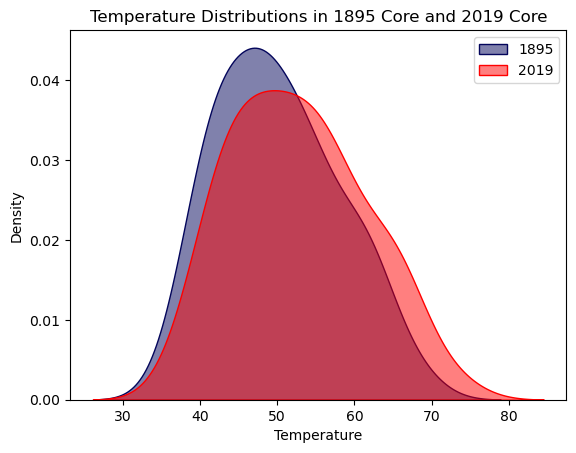

0.9655638933181763
0.16916663944721222
0.9696177244186401
0.24478162825107574
1.9855234417658298
-1.5496621921297633
0.12458300717205346


In [86]:
df = pd.read_csv('climdiv_county_year.csv')
df['state_fips'] = df['fips'].astype(str).str[:2]

df2 = pd.read_csv('Untitled spreadsheet - united states 1970-01-01 to 1971-01-01.csv')
df2_pivot = df2.pivot_table(index='datetime', values='temp', aggfunc='mean').reset_index()
df2_pivot.to_csv('Untitled spreadsheet - united states 1970-01-01 to 1971-01-01.csv', index=False)

df3 = pd.read_csv('Untitled spreadsheet - united states 2019-01-01 to 2020-01-01.csv')
df3_pivot = df3.pivot_table(index='datetime', values='temp', aggfunc='mean').reset_index()
df3_pivot.to_csv('Untitled spreadsheet - united states 2019-01-01 to 2020-01-01.csv', index=False)



df_pivot = df.pivot_table(index='state_fips', columns='year', values=['temp', 'tempc'], aggfunc='mean').reset_index()

df_pivot.to_csv('states_and_years.csv', index=False)

df_pivot2 = pd.read_csv('states_and_years - states_and_years.csv')

cols1 = df_pivot2['1895']
cols1_avg = cols1.mean()
cols2 = df_pivot2['2019']
cols2_avg = cols2.mean()
colsz = df_pivot2['1970']
colsz_avg = colsz.mean()
mu_1895, std_1895 = norm.fit(df_pivot2['1895'])
mu_2019, std_2019 = norm.fit(df_pivot2['2019'])
mu_1970, std_1970 = norm.fit(df_pivot2['1970'])


fig, ax = plt.subplots()
sns.kdeplot(df_pivot2['1895'], shade=True, label='1895', color='#03055B', alpha=0.5)
sns.kdeplot(df_pivot2['2019'], shade=True, label='2019', color='#FF0000', alpha=0.5)

ax.set_title('Temperature Distributions in 1895 Core and 2019 Core')
ax.set_xlabel('Temperature')
ax.set_ylabel('Density')
ax.legend()
plt.show()










w, p = shapiro(df_pivot2['1895'])
w2, p2 = shapiro(df_pivot2['2019'])
w3, p3 = shapiro(df_pivot2['1970'])
print(w)
print(p)
print(w2)
print(p2)

data_1895 = cols1
data_2019 = cols2
t_stat, p_val = stats.ttest_ind(data_1895, data_2019)
crit_val = stats.t.ppf(1-0.05 / 2, len(data_1895) + len(data_2019) -2)

data_1970 = colsz
t_stat2, p_val2 = stats.ttest_ind(data_1895, data_1970)
crit_val2 = stats.t.ppf(1-0.05 / 2, len(data_1895) + len(data_1970) -2)

print( crit_val)
print(t_stat)
print(p_val)



/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/467360125.py:13: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['1895'], shade=True, label='1895', color='#03055B', alpha=0.5)
/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/467360125.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['1970'], shade=True, label='1970', color='#FF0000', alpha=0.5)


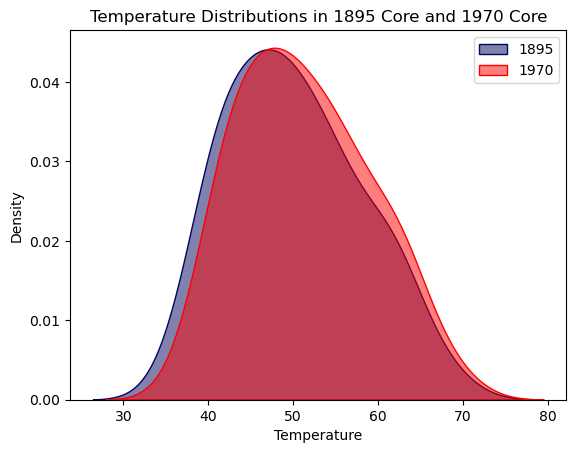

0.9679917097091675
0.21129979193210602
1.984984311431769
-0.7708908001803613
0.44270502757248786


In [99]:
cols1 = df_pivot2['1895']
cols1_avg = cols1.mean()
cols2 = df_pivot2['2019']
cols2_avg = cols2.mean()
colsz = df_pivot2['1970']
colsz_avg = colsz.mean()
mu_1895, std_1895 = norm.fit(df_pivot2['1895'])
mu_2019, std_2019 = norm.fit(df_pivot2['2019'])
mu_1970, std_1970 = norm.fit(df_pivot2['1970'])


fig, ax = plt.subplots()
sns.kdeplot(df_pivot2['1895'], shade=True, label='1895', color='#03055B', alpha=0.5)
sns.kdeplot(df_pivot2['1970'], shade=True, label='1970', color='#FF0000', alpha=0.5)

ax.set_title('Temperature Distributions in 1895 Core and 1970 Core')
ax.set_xlabel('Temperature')
ax.set_ylabel('Density')
ax.legend()
plt.show()


data_1970 = colsz
t_stat2, p_val2 = stats.ttest_ind(data_1895, data_1970)
crit_val2 = stats.t.ppf(1-0.05 / 2, len(data_1895) + len(data_1970))
print(w3)
print(p3)
print(crit_val2)
print(t_stat2)
print(p_val2)

/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/363465166.py:13: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['1970'], shade=True, label='1970', color='#03055B', alpha=0.5)
/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/363465166.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['2019'], shade=True, label='2019', color='#FF0000', alpha=0.5)


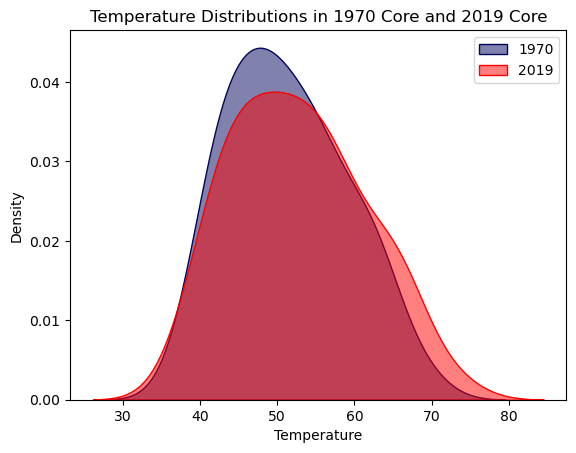

1.984984311431769
-0.8297298394135685
0.4087937572392759


In [90]:
cols1 = df_pivot2['1895']
cols1_avg = cols1.mean()
cols2 = df_pivot2['2019']
cols2_avg = cols2.mean()
colsz = df_pivot2['1970']
colsz_avg = colsz.mean()
mu_1895, std_1895 = norm.fit(df_pivot2['1895'])
mu_2019, std_2019 = norm.fit(df_pivot2['2019'])
mu_1970, std_1970 = norm.fit(df_pivot2['1970'])


fig, ax = plt.subplots()
sns.kdeplot(df_pivot2['1970'], shade=True, label='1970', color='#03055B', alpha=0.5)
sns.kdeplot(df_pivot2['2019'], shade=True, label='2019', color='#FF0000', alpha=0.5)

ax.set_title('Temperature Distributions in 1970 Core and 2019 Core')
ax.set_xlabel('Temperature')
ax.set_ylabel('Density')
ax.legend()
plt.show()

t_stat3, p_val3 = stats.ttest_ind(data_1970, data_2019)
crit_val3 = stats.t.ppf(1-0.05 / 2, len(data_1970) + len(data_2019))
                        
print(crit_val3)
print(t_stat3)
print(p_val3)

0.9413214921951294
7.543642099872017e-11
0.9424158930778503
1.009579295163654e-10
U-statistic: 57687.0
p-value: 0.001162713964829225


/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/1166715616.py:18: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df2_pivot['temp'], shade=True, label='1970 Auxiliary', color='#03055B', alpha=0.5)
/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/1166715616.py:19: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df3_pivot['temp'], shade=True, label='2019 Auxiliary', color='#FF0000', alpha=0.5)


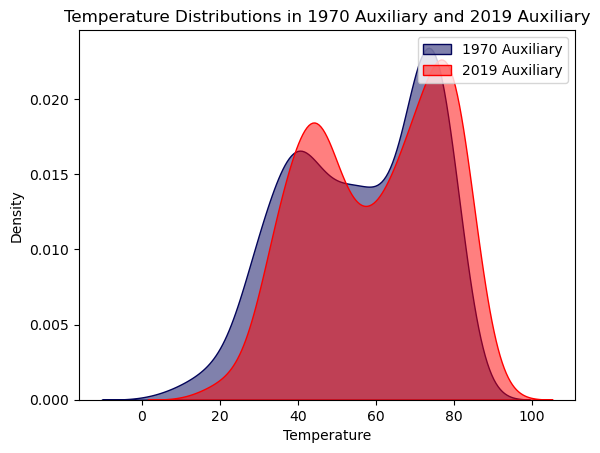

55.788797814207655
59.885245901639344


In [101]:
w_2, p_2 = shapiro(df2_pivot['temp'])
print(w_2)
print(p_2)

w_3, p_3 = shapiro(df3_pivot['temp'])
print(w_3)
print(p_3)

from scipy.stats import mannwhitneyu


u_stat, p_val = mannwhitneyu(df2_pivot['temp'], df3_pivot['temp'])

print("U-statistic:", u_stat)
print("p-value:", p_val)

fig, ax = plt.subplots()
sns.kdeplot(df2_pivot['temp'], shade=True, label='1970 Auxiliary', color='#03055B', alpha=0.5)
sns.kdeplot(df3_pivot['temp'], shade=True, label='2019 Auxiliary', color='#FF0000', alpha=0.5)

ax.set_title('Temperature Distributions in 1970 Auxiliary and 2019 Auxiliary')
ax.set_xlabel('Temperature')
ax.set_ylabel('Density')
ax.legend()
plt.show()


print(cols1_2_avg)
print(cols1_3_avg)

1.9855234417658298
-1.5496621921297633
0.12458300717205346
1.9855234417658298
-0.7708908001803613
0.44270502757248786


/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/1688011371.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['1970'], shade=True, label='1970 Core', color='#03055B', alpha=0.5)
/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/1688011371.py:7: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df2_pivot['temp'], shade=True, label='1970 Auxiliary', color='#FF0000', alpha=0.5)


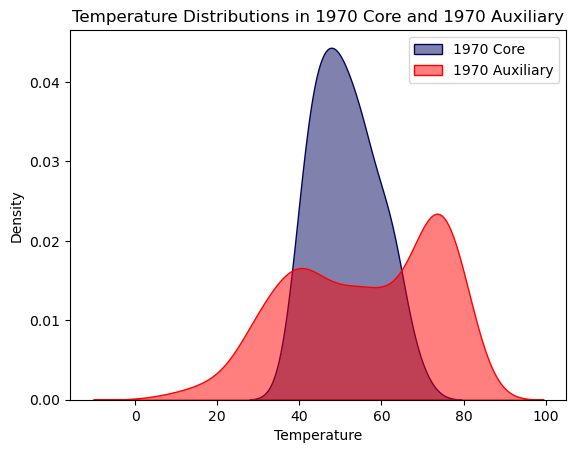

U-statistic: 7264.0
p-value: 0.051243378720134236


In [94]:
mu_1895, std_1895 = norm.fit(df_pivot2['1970'])



fig, ax = plt.subplots()
sns.kdeplot(df_pivot2['1970'], shade=True, label='1970 Core', color='#03055B', alpha=0.5)
sns.kdeplot(df2_pivot['temp'], shade=True, label='1970 Auxiliary', color='#FF0000', alpha=0.5)

ax.set_title('Temperature Distributions in 1970 Core and 1970 Auxiliary')
ax.set_xlabel('Temperature')
ax.set_ylabel('Density')
ax.legend()
plt.show()


u_stat, p_val = mannwhitneyu(df_pivot2['1970'], df2_pivot['temp'])

print("U-statistic:", u_stat)
print("p-value:", p_val)

/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/2135843672.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_pivot2['2019'], shade=True, label='2019 Core', color='#03055B', alpha=0.5)
/var/folders/nb/vy2c4sqn1v1dg86l_zhd58fr0000gn/T/ipykernel_39179/2135843672.py:7: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df3_pivot['temp'], shade=True, label='2019 Auxiliary', color='#FF0000', alpha=0.5)


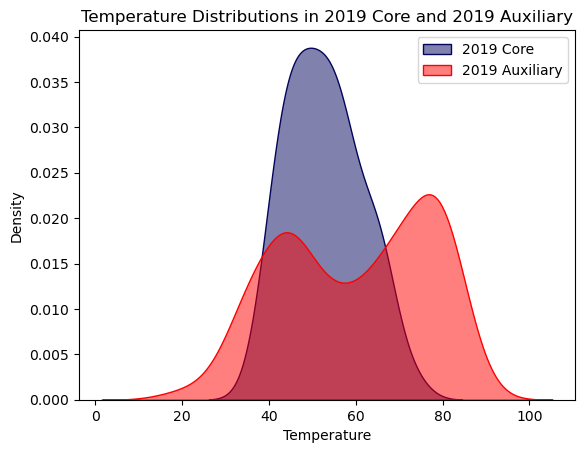

U-statistic: 6561.0
p-value: 0.0043534652747162835


In [100]:
mu_1970, std_1970 = norm.fit(df_pivot2['1970'])



fig, ax = plt.subplots()
sns.kdeplot(df_pivot2['2019'], shade=True, label='2019 Core', color='#03055B', alpha=0.5)
sns.kdeplot(df3_pivot['temp'], shade=True, label='2019 Auxiliary', color='#FF0000', alpha=0.5)

ax.set_title('Temperature Distributions in 2019 Core and 2019 Auxiliary')
ax.set_xlabel('Temperature')
ax.set_ylabel('Density')
ax.legend()
plt.show()


u_stat, p_val = mannwhitneyu(df_pivot2['2019'], df3_pivot['temp'])

print("U-statistic:", u_stat)
print("p-value:", p_val)

In [98]:
mu_2019, std_2019 = norm.fit(df_pivot2['2019'])






u_stat, p_val = mannwhitneyu(df_pivot2['2019'], df2_pivot['temp'])

print("U-statistic:", u_stat)
print("p-value:", p_val)

U-statistic: 7601.0
p-value: 0.12924565455492812


In [2]:
!pip install PyPDF2
!pip install nltk gensim wordcloud
import PyPDF2
import nltk
from nltk.corpus import stopwords
from gensim import corpora, models
from wordcloud import WordCloud

!pip install pdfplumber

In [6]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
import pdfplumber

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/nickvenditti/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/nickvenditti/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/nickvenditti/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [7]:

with open('Maximum_and_minimum_temperatures_in_the_United_Sta.pdf', 'rb') as f:
    pdf = pdfplumber.PDF(f)
    text = ''
    for page in pdf.pages:
        text += page.extract_text()


tokens = word_tokenize(text)


stop_words = set(stopwords.words('english'))
filtered_tokens = [token for token in tokens if token not in stop_words]


lemmatizer = WordNetLemmatizer()
lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]


dictionary = corpora.Dictionary([lemmatized_tokens])
corpus = [dictionary.doc2bow(lemmatized_tokens)]
lda_model = models.LdaModel(corpus, id2word=dictionary, passes=15)
topics = lda_model.print_topics(num_words=4)


for topic in topics:
    print(topic)
    



NameError: name 'word_tokenize' is not defined

In [40]:
import pdfplumber
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from gensim import corpora, models


pdf_files = ['Maximum_and_minimum_temperatures_in_the_United_Sta.pdf', 
             'Intl Journal of Climatology - 2001 - Tuomenvirta - Homogeneity adjustments of temperature and precipitation series Finnish.pdf', 
             'Intl Journal of Climatology - 2015 - Yozgatligil - Comparison of homogeneity tests for temperature using a simulation study.pdf',
            'Intl Journal of Climatology - 2014 - Nordli - The Oslo temperature series 1837 2012  homogeneity testing and temperature.pdf',
            'Intl Journal of Climatology - 2010 - Pand%C5%BEi%C4%87 - Homogeneity of average annual air temperature time series for Croatia.pdf',
            'Intl Journal of Climatology - 1998 - KEISER - Problems associated with homogeneity testing in climate variation studies  a.pdf',
            'Knapp-Correlation700mb-1992.pdf',
            'US_temperatures_Time_trends_and_persistence.pdf',
            'Lee-TrendsExtremeUS-2014.pdf',
            'retrieve.pdf']


all_text = []


for pdf_file in pdf_files:
    with pdfplumber.open(pdf_file) as pdf:
        text = ''
        for page in pdf.pages:
            text += page.extract_text()
        all_text.append(text)


all_text = ' '.join(all_text)


tokens = nltk.word_tokenize(all_text)


stop_words = set(stopwords.words('english'))
filtered_tokens = [token for token in tokens if token not in stop_words]


lemmatizer = WordNetLemmatizer()
lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]


dictionary = corpora.Dictionary([lemmatized_tokens])
corpus = [dictionary.doc2bow(lemmatized_tokens)]
lda_model = models.LdaModel(corpus, id2word=dictionary, passes=100, num_topics=5, alpha=0.1)


topics = lda_model.show_topics(num_words=20)


for topic_id, topic in enumerate(topics):
    print(f"Topic {topic_id}: {topic}")

topic_names = ["Topic {}".format(i) for i in range(len(topics))]
print("Topic Names (Themes):", topic_names)

Topic 0: (0, '0.000*"," + 0.000*"(" + 0.000*"." + 0.000*")" + 0.000*"series" + 0.000*"time" + 0.000*"1" + 0.000*"trend" + 0.000*":" + 0.000*"The" + 0.000*"station" + 0.000*"change" + 0.000*"cid:0" + 0.000*"cid:1" + 0.000*"C" + 0.000*"–" + 0.000*";" + 0.000*"data" + 0.000*"temperature" + 0.000*"2"')
Topic 1: (1, '0.000*"," + 0.000*")" + 0.000*"." + 0.000*"(" + 0.000*"series" + 0.000*":" + 0.000*"temperature" + 0.000*";" + 0.000*"The" + 0.000*"time" + 0.000*"1" + 0.000*"cid:0" + 0.000*"trend" + 0.000*"–" + 0.000*"mean" + 0.000*"station" + 0.000*"cid:1" + 0.000*"2" + 0.000*"data" + 0.000*"C"')
Topic 2: (2, '0.000*"," + 0.000*")" + 0.000*"(" + 0.000*"." + 0.000*":" + 0.000*"series" + 0.000*"temperature" + 0.000*";" + 0.000*"cid:0" + 0.000*"1" + 0.000*"–" + 0.000*"The" + 0.000*"trend" + 0.000*"station" + 0.000*"cid:1" + 0.000*"time" + 0.000*"data" + 0.000*"2" + 0.000*"%" + 0.000*"*"')
Topic 3: (3, '0.000*"," + 0.000*")" + 0.000*"." + 0.000*"(" + 0.000*":" + 0.000*"series" + 0.000*"cid:0" + 

In [41]:

topics = lda_model.show_topics(num_words=20)


for topic_id, topic in enumerate(topics):
    print(f"Topic {topic_id}: {topic}")

    
    top_words = [word for word in topic[1]]  

    
    sentence = " ".join(top_words)
    sentence = sentence.replace(" ,", ",").replace(" .", ".")

    
    sentence = sentence.capitalize() + "."

    print(f"Topic {topic_id} Sentence: {sentence}")

topic_names = ["Topic {}".format(i) for i in range(len(topics))]
print("Topic Names (Themes):", topic_names)

Topic 0: (0, '0.000*"," + 0.000*"(" + 0.000*"." + 0.000*")" + 0.000*"series" + 0.000*"time" + 0.000*"1" + 0.000*"trend" + 0.000*":" + 0.000*"The" + 0.000*"station" + 0.000*"change" + 0.000*"cid:0" + 0.000*"cid:1" + 0.000*"C" + 0.000*"–" + 0.000*";" + 0.000*"data" + 0.000*"temperature" + 0.000*"2"')
Topic 0 Sentence: 0. 0 0 0 * ", "   +   0. 0 0 0 * " ( "   +   0. 0 0 0 * ". "   +   0. 0 0 0 * " ) "   +   0. 0 0 0 * " s e r i e s "   +   0. 0 0 0 * " t i m e "   +   0. 0 0 0 * " 1 "   +   0. 0 0 0 * " t r e n d "   +   0. 0 0 0 * " : "   +   0. 0 0 0 * " t h e "   +   0. 0 0 0 * " s t a t i o n "   +   0. 0 0 0 * " c h a n g e "   +   0. 0 0 0 * " c i d : 0 "   +   0. 0 0 0 * " c i d : 1 "   +   0. 0 0 0 * " c "   +   0. 0 0 0 * " – "   +   0. 0 0 0 * " ; "   +   0. 0 0 0 * " d a t a "   +   0. 0 0 0 * " t e m p e r a t u r e "   +   0. 0 0 0 * " 2 ".
Topic 1: (1, '0.000*"," + 0.000*")" + 0.000*"." + 0.000*"(" + 0.000*"series" + 0.000*":" + 0.000*"temperature" + 0.000*";" + 0.000*"The" 

In [42]:

topics = lda_model.show_topics(num_words=20)


for topic_id, topic in enumerate(topics):
    print(f"Topic {topic_id}: {topic}")
    
   
    top_words = topic[1].split('+')
    top_words = [word.strip().split('*')[1] for word in top_words]
    
    
    sentence = " ".join(top_words)
    sentence = sentence.replace(" ,", ",").replace(" .", ".")
    
   
    sentence = sentence.capitalize() + "."
    
    print(f"Topic {topic_id} Sentence: {sentence}")

topic_names = ["Topic {}".format(i) for i in range(len(topics))]
print("Topic Names (Themes):", topic_names)

Topic 0: (0, '0.000*"," + 0.000*"(" + 0.000*"." + 0.000*")" + 0.000*"series" + 0.000*"time" + 0.000*"1" + 0.000*"trend" + 0.000*":" + 0.000*"The" + 0.000*"station" + 0.000*"change" + 0.000*"cid:0" + 0.000*"cid:1" + 0.000*"C" + 0.000*"–" + 0.000*";" + 0.000*"data" + 0.000*"temperature" + 0.000*"2"')
Topic 0 Sentence: "," "(" "." ")" "series" "time" "1" "trend" ":" "the" "station" "change" "cid:0" "cid:1" "c" "–" ";" "data" "temperature" "2".
Topic 1: (1, '0.000*"," + 0.000*")" + 0.000*"." + 0.000*"(" + 0.000*"series" + 0.000*":" + 0.000*"temperature" + 0.000*";" + 0.000*"The" + 0.000*"time" + 0.000*"1" + 0.000*"cid:0" + 0.000*"trend" + 0.000*"–" + 0.000*"mean" + 0.000*"station" + 0.000*"cid:1" + 0.000*"2" + 0.000*"data" + 0.000*"C"')
Topic 1 Sentence: "," ")" "." "(" "series" ":" "temperature" ";" "the" "time" "1" "cid:0" "trend" "–" "mean" "station" "cid:1" "2" "data" "c".
Topic 2: (2, '0.000*"," + 0.000*")" + 0.000*"(" + 0.000*"." + 0.000*":" + 0.000*"series" + 0.000*"temperature" + 0